In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import  transforms
from torch.utils.data import DataLoader , Dataset

import numpy as np
import pandas as pd

from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {device}")

Device : cuda


In [3]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "scripts")))
from train import run_experiment, compare_runs

EXPERIMENT_NAME = "infrared-solar-custom-cnn"

d:\Computer Vision Engineer\infrared-solar\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [5]:
DATA_DIR = os.path.join("..", "data")

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
val = pd.read_csv(os.path.join(DATA_DIR, "val.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

print(f"Train : {len(train)}")
print(f"Val   : {len(val)}")
print(f"Test  : {len(test)}")

classes = sorted(pd.concat([train, val, test])["label"].unique())
label2idx = {c: i for i, c in enumerate(classes)}
idx2label = {i: c for c, i in label2idx.items()}

print(f"\n{len(classes)} classes : {label2idx}")

Train : 12780
Val   : 3195
Test  : 3994

12 classes : {'Cell': 0, 'Cell-Multi': 1, 'Cracking': 2, 'Diode': 3, 'Diode-Multi': 4, 'Hot-Spot': 5, 'Hot-Spot-Multi': 6, 'No-Anomaly': 7, 'Offline-Module': 8, 'Shadowing': 9, 'Soiling': 10, 'Vegetation': 11}


In [6]:
class CreateDataset(Dataset):
    def __init__(self, dataframe, transform=None, label2idx=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label2idx = label2idx

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        img_path = row["filepath"]
        label = self.label2idx[row["label"]]

        image = Image.open(img_path).convert("L")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [7]:
dataset_train_with_label = CreateDataset(train, transform=train_transform, label2idx=label2idx)
dataset_val_with_label = CreateDataset(val, transform=eval_transform, label2idx=label2idx)
dataset_test_with_label = CreateDataset(test, transform=eval_transform, label2idx=label2idx)


train_with_label_loader = DataLoader(dataset_train_with_label, batch_size=32, shuffle=True)
val_with_label_loader = DataLoader(dataset_val_with_label, batch_size=64, shuffle=False)
test_with_label_loader = DataLoader(dataset_test_with_label, batch_size=64, shuffle=False)

images, labels = next(iter(train_with_label_loader))
print(images.shape, labels.shape, labels.min().item(), labels.max().item())

torch.Size([32, 1, 40, 24]) torch.Size([32]) 0 11


In [8]:
class SimpleCNN(nn.Module):
    def __init__(self, n_classes=12, in_ch=1):
        super().__init__()
        
        def block(i, o):
            return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                    nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                    nn.MaxPool2d(2)]

        self.features = nn.Sequential(
            *block(in_ch, 32),
            *block(32, 64),
            *block(64, 128),
        )
        self.pool = nn.AdaptiveAvgPool2d((5, 3))
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(128 * 5 * 3, n_classes))
        
    def forward(self, x):
        x = self.features(x)
        return self.head(self.pool(x).flatten(1))

model = SimpleCNN(n_classes=len(classes)).to(device)
print(model)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1,

In [9]:
 
counts = train["label"].map(label2idx).value_counts().sort_index()
class_weights = torch.tensor(
    (len(train) / (len(classes) * counts.values)), dtype=torch.float32
).to(device)

print(pd.Series(class_weights.cpu().numpy(), index=classes).round(3))

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = optim.Adam(model.parameters(), lr=0.001)

Cell              0.887
Cell-Multi        1.292
Cracking          1.778
Diode             1.113
Diode-Multi       9.509
Hot-Spot          6.698
Hot-Spot-Multi    6.741
No-Anomaly        0.166
Offline-Module    2.032
Shadowing         1.592
Soiling           8.130
Vegetation        1.016
dtype: float32


In [10]:
result = run_experiment(
    model, criterion, optimizer,
    train_with_label_loader, val_with_label_loader, test_with_label_loader,
    classes=classes,
    experiment_name=EXPERIMENT_NAME,
    run_name="simplecnn-weighted-aug",
    num_epochs=15,
    device=device,
    log_grads_every=50,
    grad_clip=None,
    params={
        "input_shape": "1x40x24",
        "dropout": 0.3,
        "class_weighting": "balanced",
        "augmentation": "hflip+vflip",
        "normalize": "mean=0.5, std=0.5",
    },
    tags={"dataset": "dataset_eda", "task": "multiclass-12", "stage": "baseline"},
)

Epoch [1/15] train_loss: 2.3319 | val_loss: 1.9735 | val_f1_macro: 0.2648  <- best
Epoch [2/15] train_loss: 1.8596 | val_loss: 1.8701 | val_f1_macro: 0.2238
Epoch [3/15] train_loss: 1.6716 | val_loss: 1.6646 | val_f1_macro: 0.3774  <- best
Epoch [4/15] train_loss: 1.5532 | val_loss: 1.6108 | val_f1_macro: 0.3621
Epoch [5/15] train_loss: 1.4611 | val_loss: 1.3593 | val_f1_macro: 0.4378  <- best
Epoch [6/15] train_loss: 1.3981 | val_loss: 1.3839 | val_f1_macro: 0.4468  <- best
Epoch [7/15] train_loss: 1.3457 | val_loss: 1.3831 | val_f1_macro: 0.3751
Epoch [8/15] train_loss: 1.2982 | val_loss: 1.3184 | val_f1_macro: 0.4302
Epoch [9/15] train_loss: 1.2370 | val_loss: 1.2694 | val_f1_macro: 0.4492  <- best
Epoch [10/15] train_loss: 1.2075 | val_loss: 1.2250 | val_f1_macro: 0.4999  <- best
Epoch [11/15] train_loss: 1.1835 | val_loss: 1.1875 | val_f1_macro: 0.4730
Epoch [12/15] train_loss: 1.1312 | val_loss: 1.1469 | val_f1_macro: 0.4987
Epoch [13/15] train_loss: 1.1151 | val_loss: 1.2070 | v

2026/10/13 04:15:03 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/13 04:15:03 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/13 04:15:12 WARNING mlflow.utils.requirements_utils: Found torch version (2.7.1+cu118) contains a local version label (+cu118). MLflow logged a pip requirement for this package as 'torch==2.7.1' without the local version label 


Run MLflow : 879e9e710b164088b94c34bad8ebeebd
Visualiser : mlflow ui --backend-store-uri "sqlite:///D:/Computer Vision Engineer/infrared-solar/mlflow.db"


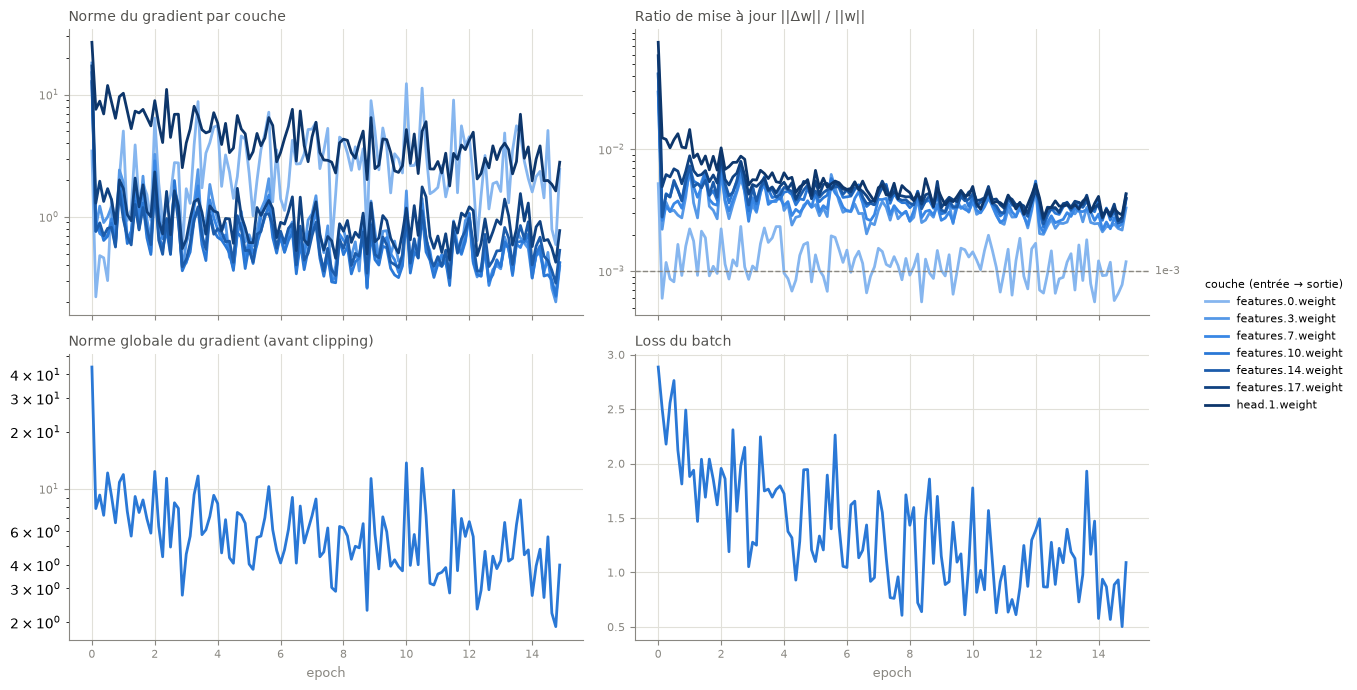

In [11]:
result["dynamics_figure"]

AUC ROC macro (ovr) : 0.9384

Offline-Module    0.8929
Shadowing         0.9007
Cell-Multi        0.9013
Soiling           0.9175
Cell              0.9184
Vegetation        0.9256
No-Anomaly        0.9448
Hot-Spot-Multi    0.9564
Hot-Spot          0.9626
Cracking          0.9657
Diode-Multi       0.9856
Diode             0.9888


pred,Cell,Cell-Multi,Cracking,Diode,Diode-Multi,Hot-Spot,Hot-Spot-Multi,No-Anomaly,Offline-Module,Shadowing,Soiling,Vegetation
true,,,,,,,,,,,,
Cell,130,112,4,1,5,9,2,17,8,10,10,67
Cell-Multi,23,135,31,6,1,6,3,7,5,5,14,21
Cracking,3,30,125,0,0,1,11,1,1,4,8,4
Diode,0,1,0,275,7,2,0,6,4,2,0,2
Diode-Multi,0,1,0,3,28,0,0,1,1,1,0,0
Hot-Spot,1,1,0,1,0,33,4,3,3,3,0,1
Hot-Spot-Multi,1,0,2,1,1,5,29,3,5,0,0,2
No-Anomaly,12,22,1,26,22,83,39,1424,225,120,4,21
Offline-Module,3,2,0,2,7,1,3,37,101,7,0,2


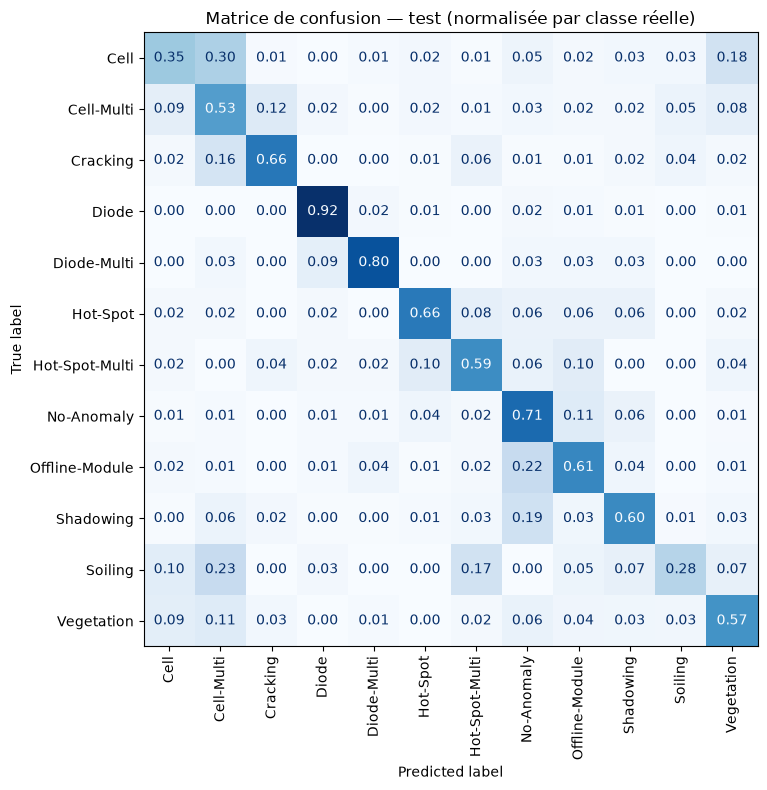

In [12]:
print(f"AUC ROC macro (ovr) : {result['roc_auc']['global']:.4f}\n")
print(pd.Series(result["roc_auc"]["per_class"], name="auc").sort_values().round(4).to_string())

display(result["confusion_matrix"])
result["figure"]

In [13]:
preds = result["predictions"]
correct = preds[preds["correct"]]
errors = preds[~preds["correct"]]
print(f"Correct : {len(correct)} | Errors : {len(errors)}")

display(errors.groupby(["label", "pred_label"]).size().sort_values(ascending=False).head(10))

display(errors.sort_values("confidence", ascending=False)
        [["filepath", "label", "pred_label", "confidence", "prob_true"]].head(15))

Bons : 2604 | Erreurs : 1390


label           pred_label    
No-Anomaly      Offline-Module    225
                Shadowing         120
Cell            Cell-Multi        112
No-Anomaly      Hot-Spot           83
Cell            Vegetation         67
No-Anomaly      Hot-Spot-Multi     39
Shadowing       No-Anomaly         39
Offline-Module  No-Anomaly         37
Vegetation      Cell-Multi         37
Cell-Multi      Cracking           31
dtype: int64

,filepath,label,pred_label,confidence,prob_true
1500,d:\Computer Vision Engineer\infrared-solar\dat...,Offline-Module,Diode-Multi,0.999006,0.000566
3877,d:\Computer Vision Engineer\infrared-solar\dat...,Diode-Multi,Diode,0.994152,0.005779
526,d:\Computer Vision Engineer\infrared-solar\dat...,Soiling,Diode,0.994105,0.000021
3652,d:\Computer Vision Engineer\infrared-solar\dat...,Cell-Multi,Cracking,0.987862,0.009144
1048,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,Shadowing,0.987596,0.000999
246,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,Shadowing,0.986010,0.002848
816,d:\Computer Vision Engineer\infrared-solar\dat...,Hot-Spot-Multi,Hot-Spot,0.983356,0.013884
1913,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,Diode,0.982840,0.000390
1027,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,Hot-Spot,0.980200,0.001575
2397,d:\Computer Vision Engineer\infrared-solar\dat...,No-Anomaly,Hot-Spot,0.977781,0.008924


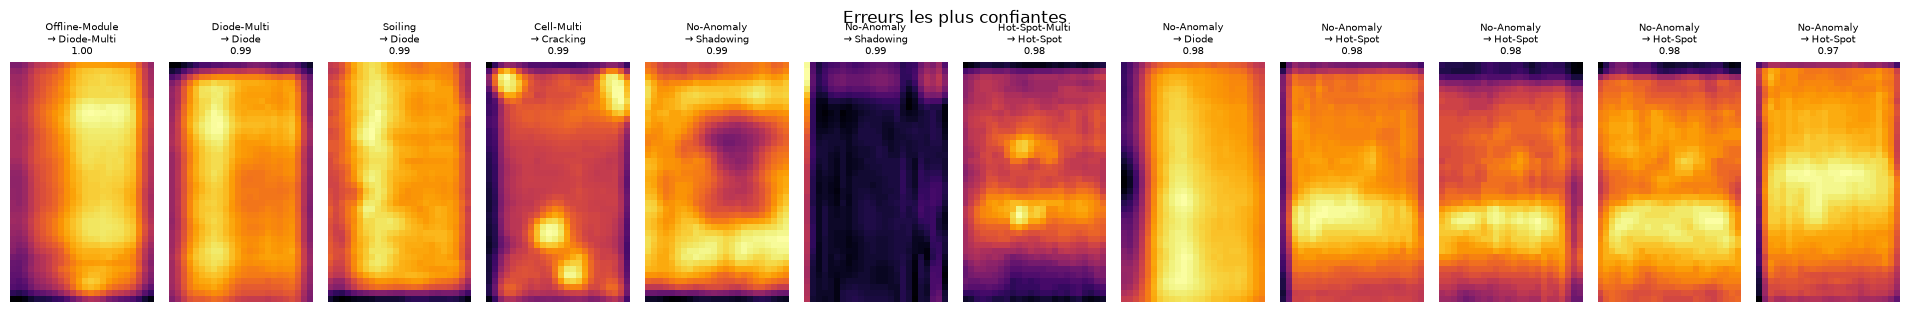

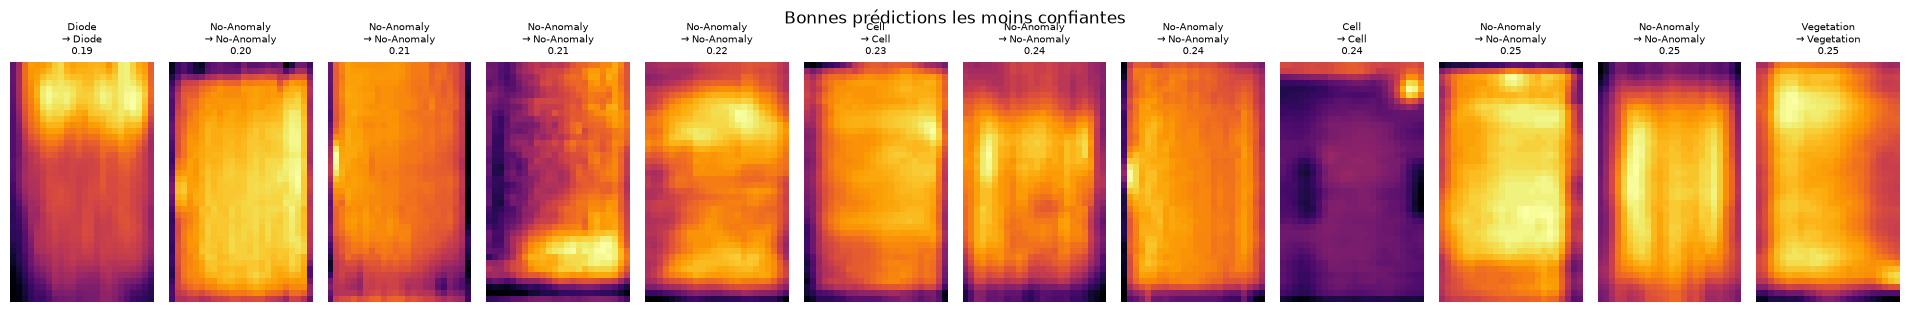

In [14]:
import matplotlib.pyplot as plt

def show_grid(df, n=12, title=""):
    df = df.head(n)
    fig, axes = plt.subplots(1, len(df), figsize=(1.6 * len(df), 3.2), squeeze=False)
    for ax, (_, r) in zip(axes[0], df.iterrows()):
        ax.imshow(Image.open(r["filepath"]).convert("L"), cmap="inferno")
        ax.set_title(f"{r['label']}\n→ {r['pred_label']}\n{r['confidence']:.2f}", fontsize=7)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_grid(errors.sort_values("confidence", ascending=False), title="Most confident errors")
show_grid(correct.sort_values("confidence"), title="Least confident correct predictions")

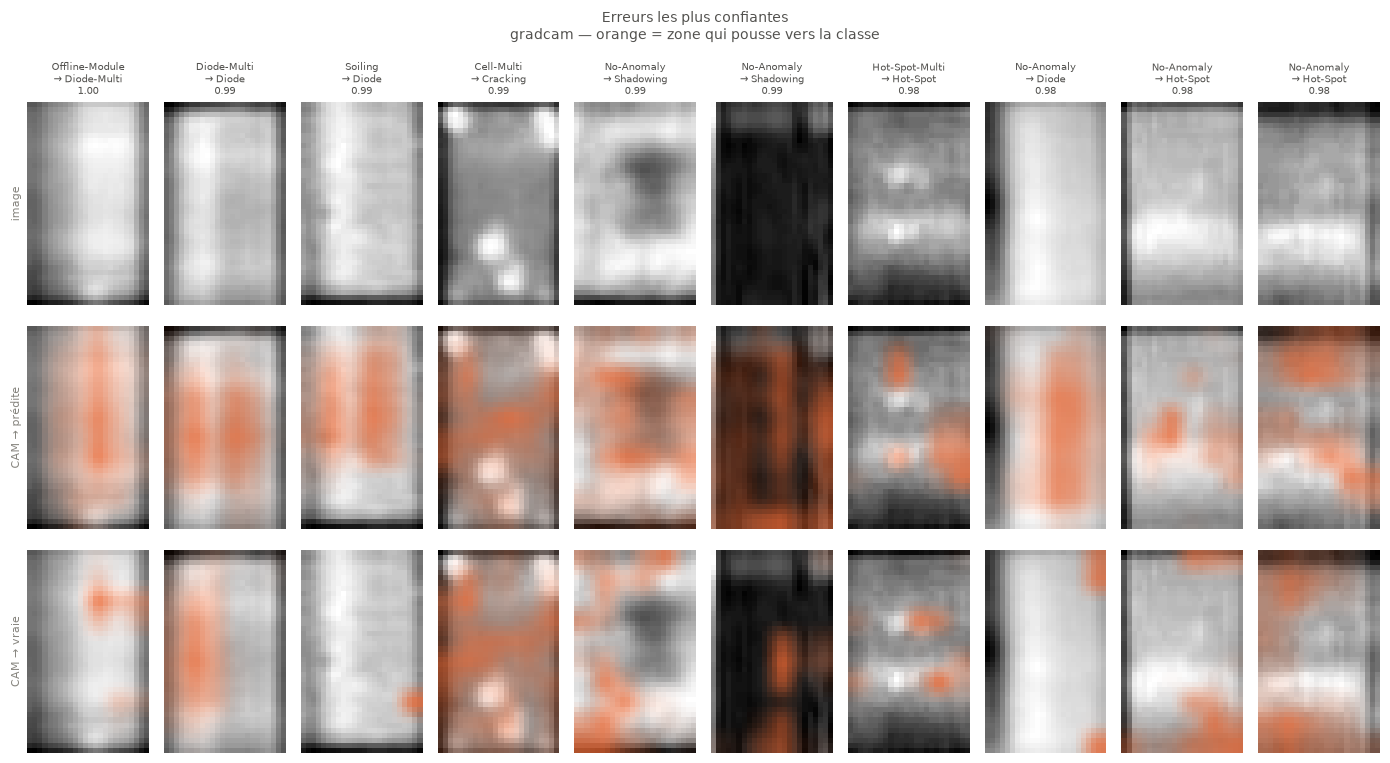

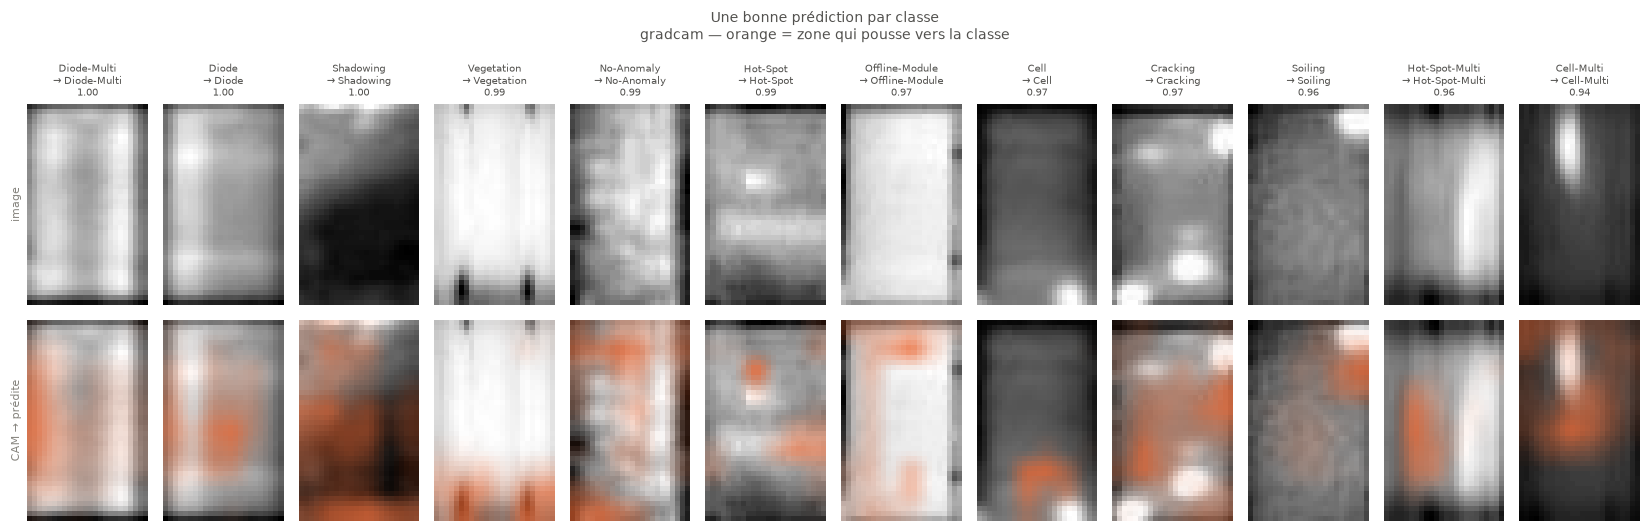

In [15]:
from explain import show_gradcam, extract_embeddings, embedding_map, plot_embedding_map, log_figures

TARGET_LAYER = model.features[19]
CAM_METHOD = "gradcam"

preds = result["predictions"]

confident_errors = preds[~preds["correct"]].nlargest(10, "confidence")
fig_cam_err = show_gradcam(model, dataset_test_with_label, confident_errors.index, TARGET_LAYER, classes,
                           targets=("pred", "true"), method=CAM_METHOD,
                           title="Most confident errors")

best_per_class = preds[preds["correct"]].sort_values("confidence", ascending=False).groupby("label").head(1)
fig_cam_ok = show_gradcam(model, dataset_test_with_label, best_per_class.index, TARGET_LAYER, classes,
                          targets=("pred",), method=CAM_METHOD, title="One correct prediction per class")
display(fig_cam_err, fig_cam_ok)

d:\Computer Vision Engineer\infrared-solar\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


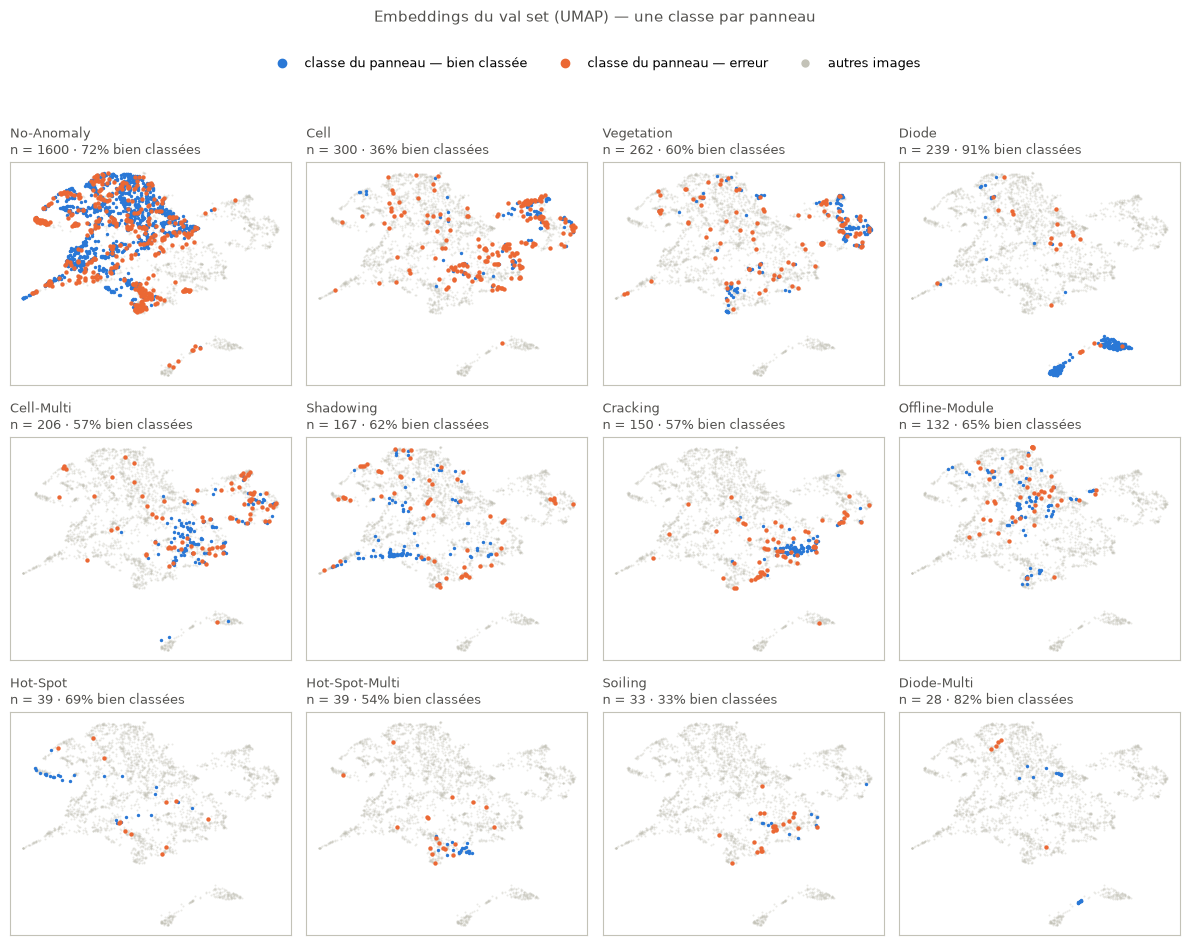

In [16]:
emb_val, y_val, y_val_pred = extract_embeddings(model, val_with_label_loader, model.pool)
xy_val = embedding_map(emb_val, method="umap")

fig_umap = plot_embedding_map(xy_val, groups=[classes[i] for i in y_val], correct=y_val == y_val_pred,
                              title="Val set embeddings (UMAP), one class per panel")
display(fig_umap)

log_figures(result["run_id"], {
    "explain/gradcam_errors.png": fig_cam_err,
    "explain/gradcam_correct.png": fig_cam_ok,
    "explain/umap_val.png": fig_umap,
})

In [17]:
print(compare_runs(EXPERIMENT_NAME).to_string(index=False))

                          run_id    tags.mlflow.runName  metrics.best_val_f1_macro  metrics.test_f1_macro  metrics.test_roc_auc_ovr  metrics.test_accuracy params.model params.lr params.num_epochs                       start_time
879e9e710b164088b94c34bad8ebeebd simplecnn-weighted-aug                   0.526219               0.512578                  0.938366               0.651978    SimpleCNN     0.001                15 2026-10-13 02:10:18.038000+00:00
